# 🏠 House Price Predictor — EDA & Modeling
End-to-end walkthrough: data → EDA → features → models → evaluation.

Run from the `notebooks/` folder.

In [1]:
import sys; sys.path.append('../src')
import pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns, joblib, json
sns.set_theme(style='whitegrid')
df = pd.read_csv('../data/raw/housing.csv')
df.head()

,sqft,bedrooms,bathrooms,year_built,lot_size,garage_spaces,overall_quality,has_pool,dist_to_center_km,neighborhood,price
0,2143.0,3,2,2000.0,7107.0,2,4,0,4.6,Eastgate,225200.0
1,1136.0,1,2,1967.0,2310.0,1,7,1,7.7,Greenfield,232600.0
2,567.0,1,2,1974.0,1828.0,2,9,0,17.4,Eastgate,129600.0
3,798.0,1,1,1958.0,1191.0,1,7,1,7.2,Oakwood,138000.0
4,2435.0,4,4,1956.0,7140.0,1,8,0,3.9,Downtown,437700.0


## 1. Data quality

In [2]:
print(df.shape)
display(df.describe().T.round(1))
print('\nMissing %:'); print((df.isna().mean()*100).round(2)[lambda s: s>0])

(3000, 11)


,count,mean,std,min,25%,50%,75%,max
sqft,3000.0,1581.7,572.8,500.0,1171.0,1489.0,1863.2,4959.0
bedrooms,3000.0,2.5,1.1,1.0,2.0,2.0,3.0,7.0
bathrooms,3000.0,2.1,0.8,1.0,1.0,2.0,3.0,5.0
year_built,2936.0,1973.4,28.7,1925.0,1948.0,1973.0,1998.0,2023.0
lot_size,2887.0,4549.7,2271.8,1000.0,2895.0,4154.0,5715.5,17389.0
garage_spaces,3000.0,1.7,0.9,0.0,1.0,2.0,2.0,3.0
overall_quality,3000.0,6.0,1.5,1.0,5.0,6.0,7.0,10.0
has_pool,3000.0,0.1,0.3,0.0,0.0,0.0,0.0,1.0
dist_to_center_km,2908.0,6.6,4.8,0.3,3.2,5.6,8.8,40.0
price,3000.0,245919.3,94365.7,35200.0,179575.0,233550.0,298500.0,733200.0



Missing %:
year_built           2.13
lot_size             3.77
dist_to_center_km    3.07
dtype: float64


## 2. Target distribution
Price is right-skewed → we model `log1p(price)` and invert at prediction time.

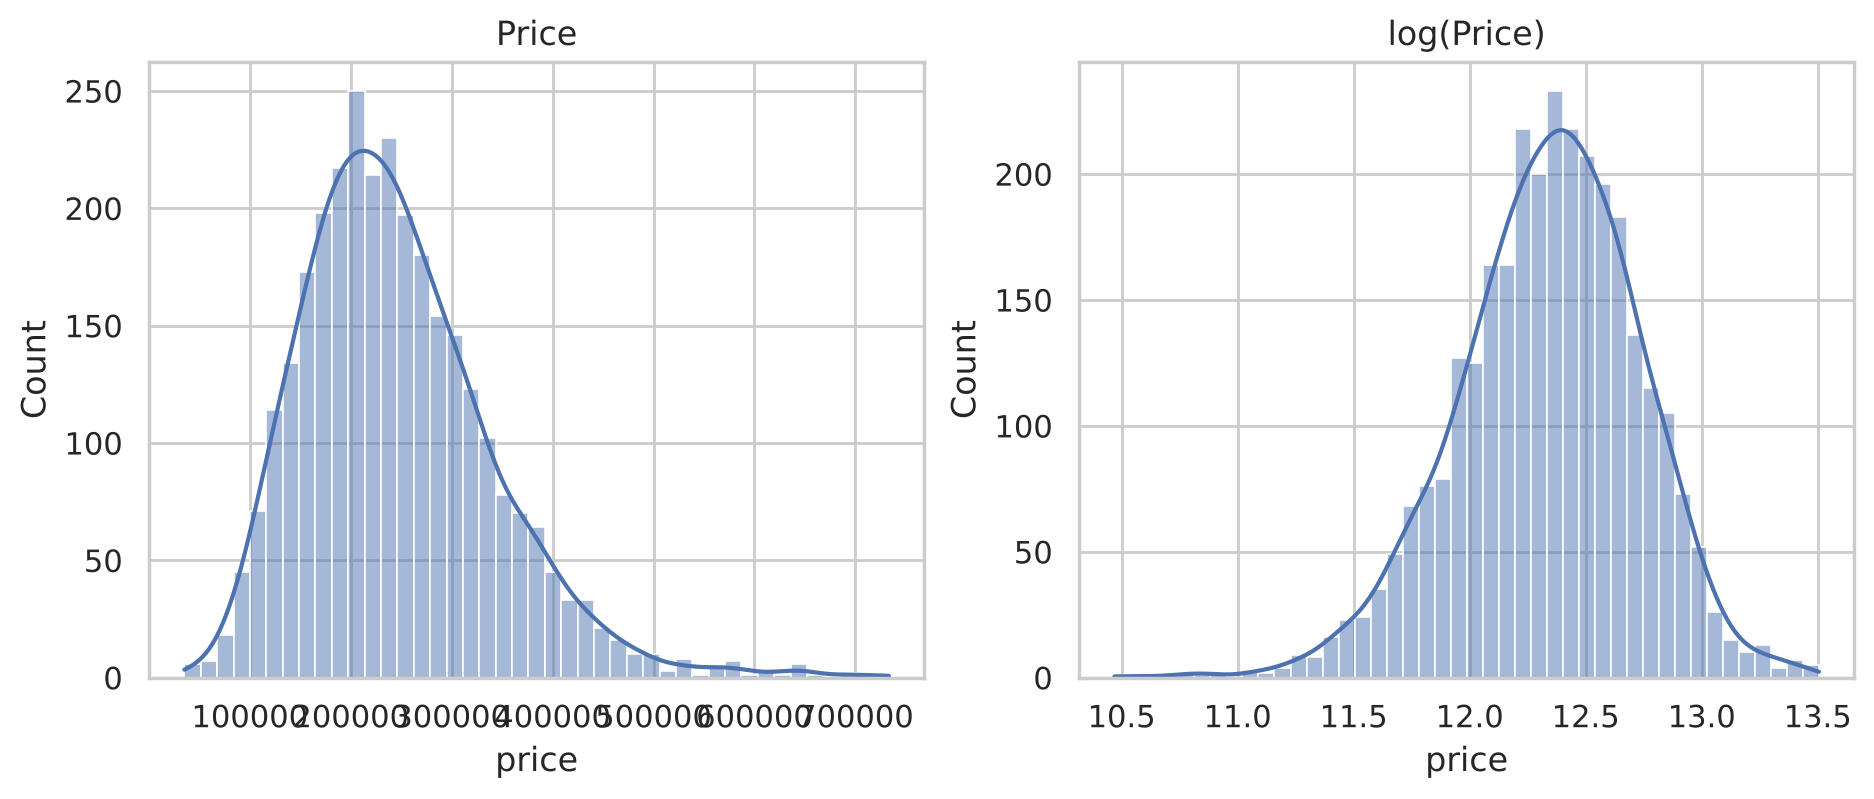

Skew: 0.97


In [3]:
fig,ax=plt.subplots(1,2,figsize=(11,4))
sns.histplot(df.price,kde=True,ax=ax[0]); sns.histplot(np.log(df.price),kde=True,ax=ax[1])
ax[0].set_title('Price'); ax[1].set_title('log(Price)'); plt.show()
print('Skew:', round(df.price.skew(),2))

## 3. What drives price?

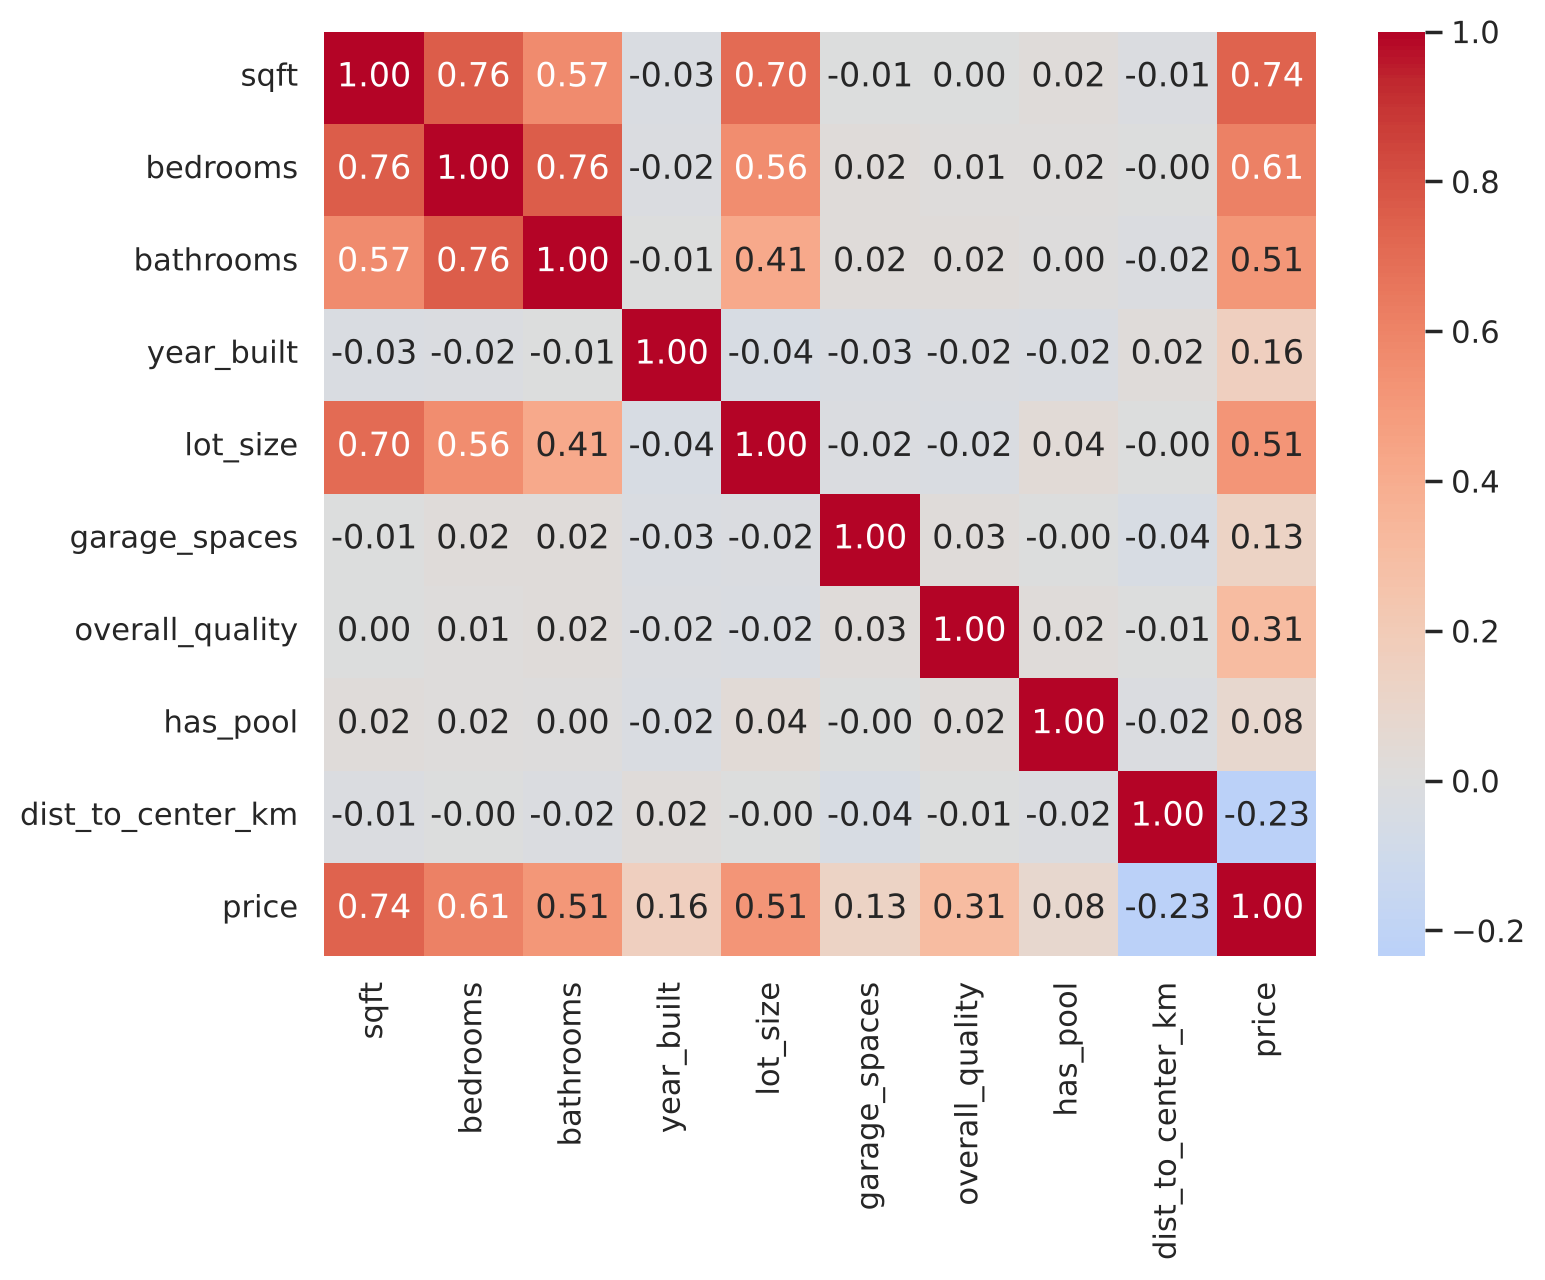

In [4]:
plt.figure(figsize=(8,6)); sns.heatmap(df.select_dtypes('number').corr(),annot=True,fmt='.2f',cmap='coolwarm',center=0); plt.show()

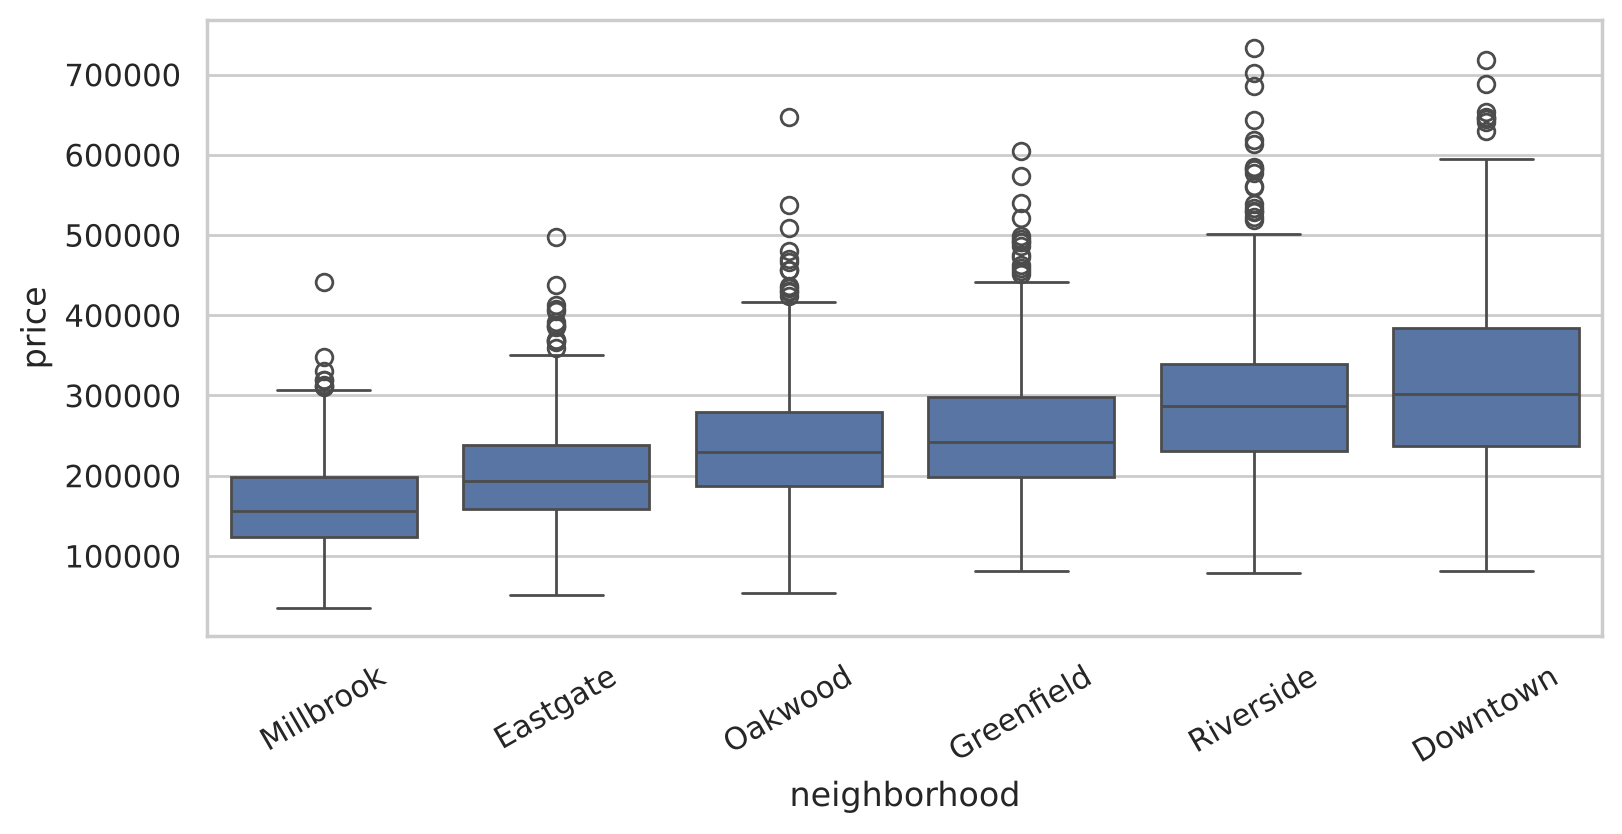

In [5]:
order=df.groupby('neighborhood').price.median().sort_values().index
plt.figure(figsize=(9,4)); sns.boxplot(data=df,x='neighborhood',y='price',order=order); plt.xticks(rotation=30); plt.show()

**Insights:** `sqft` is the strongest single correlate; neighborhood shifts the whole price level (Downtown ≈ 1.9× Millbrook); quality and age matter after controlling for size.

## 4. Feature engineering & pipeline
See `src/features.py`: median imputation + scaling for numerics, one-hot for neighborhood, plus `house_age`, `sqft_per_bedroom`, `bath_bed_ratio`.

## 5. Model comparison

In [6]:
m = json.load(open('../reports/metrics.json'))
pd.DataFrame(m['models']).T[['cv_r2_mean','r2','mae','rmse','mape_pct']]

,cv_r2_mean,r2,mae,rmse,mape_pct
Ridge (baseline),0.8718,0.9176,18668.0,26441.0,7.85
Random Forest,0.8960,0.9043,21429.0,28494.0,9.10
Gradient Boosting,0.9396,0.9389,16782.0,22754.0,7.08
Gradient Boosting (tuned),0.9450,0.9468,15407.0,21240.0,6.41


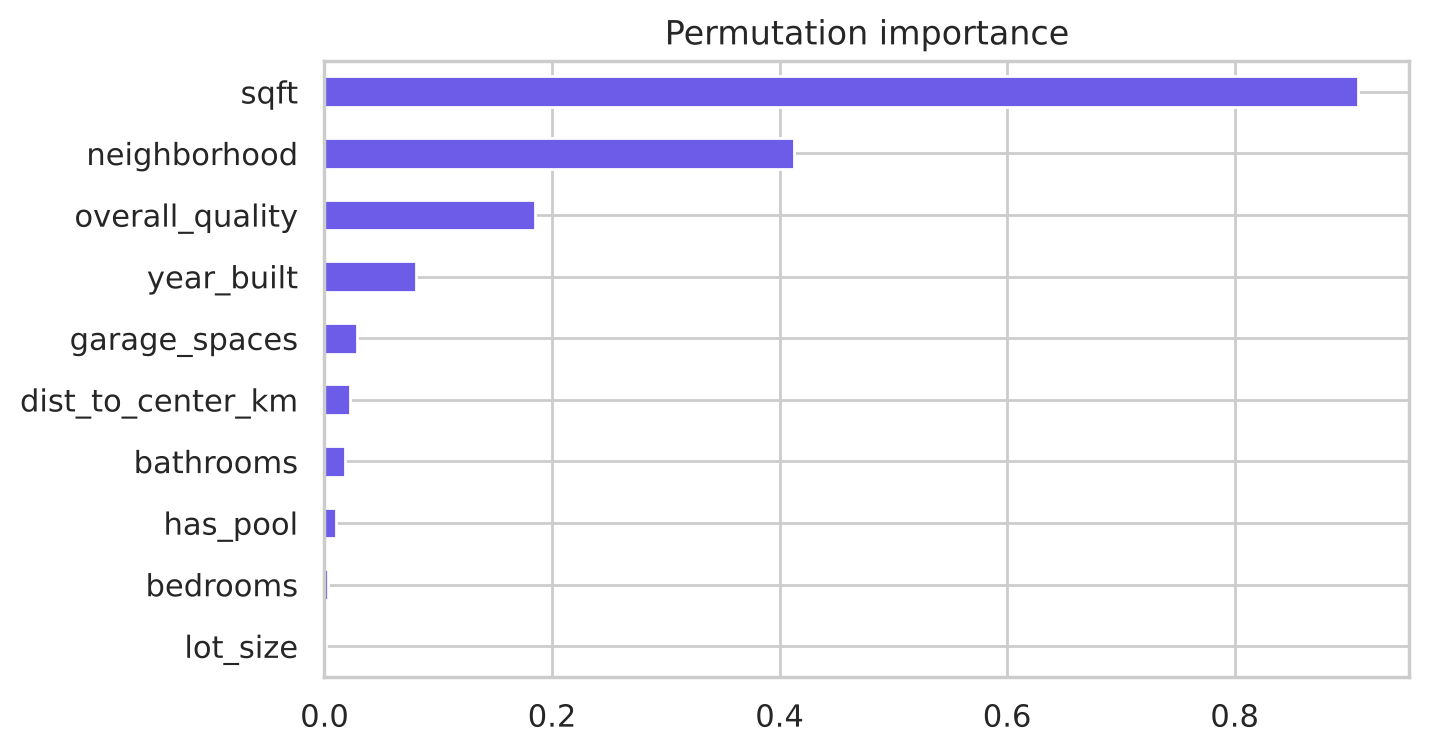

In [7]:
pd.Series(m['feature_importance']).sort_values().plot.barh(figsize=(7,4),color='#6c5ce7',title='Permutation importance'); plt.show()

## 6. Try the saved model

In [8]:
model = joblib.load('../models/house_price_model.joblib')
sample = pd.DataFrame([dict(sqft=2200,bedrooms=4,bathrooms=3,year_built=2015,lot_size=7000,garage_spaces=2,overall_quality=8,has_pool=1,dist_to_center_km=4,neighborhood='Riverside')])
print(f'Predicted: ${model.predict(sample)[0]:,.0f}')

Predicted: $488,095


## 7. Conclusions & next steps
- Tuned Gradient Boosting beats Ridge and Random Forest on hold-out R², MAE and MAPE.
- Next: SHAP explanations, prediction intervals (quantile regression), real-data swap (Ames/Kaggle), Docker + CI.